In [8]:
import numpy,pandas,json,sys
from matplotlib import pyplot
import matplotlib.patches as patches

from geochemistry_helpers import Sampling,GaussianProcess

sys.path.append("../../code/utility")
from load_data import load_cadmium,split_data_by_site,load_carbon

# Set default dpi for saving
pyplot.rcParams['savefig.dpi'] = 600

In [9]:
# Load in data
## Data
data_directory = "../../data/"
d114cd_data = load_cadmium(data_directory)
svalbard_cd_data,arctic_cd_data,northsea_cd_data,kheu_cd_data = split_data_by_site(d114cd_data)

# Collate the ages
ages = d114cd_data["Age model"].values

# Load in GP
d114cd_gp = GaussianProcess().fromJSON(data_directory+"/output/d114cd_gp.json")
d13C_gp = GaussianProcess().fromJSON(data_directory+"/output/d13c_gp.json")

# Load in prior_results
with open(data_directory+"/output/invert_organic_prior_results.json","r") as file:
    prior_results = json.load(file)
# Load in posterior_results
with open(data_directory+"/output/invert_organic_posterior_results.json","r") as file:
    posterior_results = json.load(file)

# Load in metrics
prior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_prior_metrics.xlsx")
posterior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_posterior_metrics.xlsx")

timestep = prior_metrics["time"].values[0]-prior_metrics["time"].values[1]


[0.5651468423297605, 1.9235478235127015, 1.5467171266498145, 1.8148411169488066, 2.511979369388195, 0.46656747394059794, 2.445907710272025, 1.5240650507807276, 1.0061275838325636, 1.2064805847521687, 2.862014746328972, 1.5721021624320883, 2.6535968935046035, 0.6685200961533577, 2.868639926645013, 1.5084509601033833, 1.1390380785393632, 1.3500948530476429, 2.1276121505669296, 0.3789705498476078, 2.7393556782552673, 1.282524163761468, 0.6507366164353042, 1.1473464854336688, 0.3530393805246019, 1.3994889561071728, 1.2948923409854705, 1.681936838665049, 1.0660554205254833, 1.3749904878938388, 1.8022382957974168, 0.5249035761595932, 2.7925900906563483, 2.4046473841687686, 1.805993491988301, 2.403337012649957, 2.3091370718299795, 1.4874618797132995, 0.4041563478991905, 1.9649921613570904, 1.565831668310691, 0.8400991219326261, 2.5129727024930055, 0.7572874669991563, 2.92410151117708, 1.2306308797011274, 2.8412895752617398, 2.6127318600875964, 2.2571541575886807, 0.4778567991002972, 1.0429596

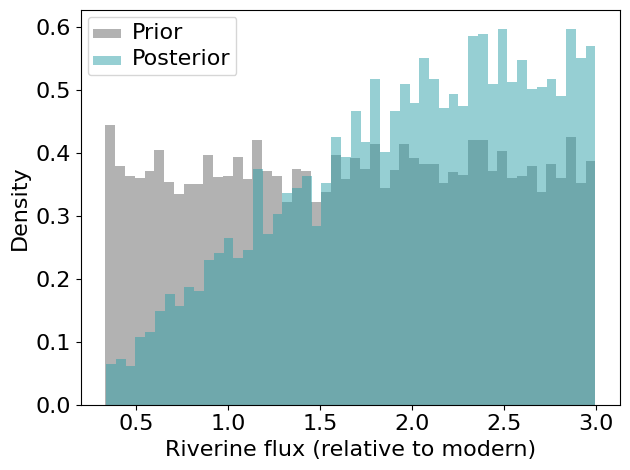

In [10]:
original_input_isotopes = json.load(open(data_directory+'/output/original_initial_conditions.json','r'))['input_multiplier']
prior_initial_input_isotopes = numpy.array([model["input_mass"][0]/30000000.0 for model in prior_results])
posterior_initial_input_isotopes = numpy.array([model["input_mass"][0]/30000000.0 for model in posterior_results])

print(original_input_isotopes)

figure = pyplot.figure()
axes = figure.add_subplot(111)

axes.hist(original_input_isotopes,bins=50,density=True,color="#666666",alpha=0.5)
# axes.hist(prior_initial_input_isotopes,bins=50,density=True,color="#94babd",alpha=0.5)
axes.hist(posterior_initial_input_isotopes,bins=50,density=True,color="#2ea0a8",alpha=0.5)

axes.set_xlabel("Riverine flux (relative to modern)")
axes.set_ylabel("Density")

axes.legend(["Prior","Posterior"])
# # Legend
# axes.legend([handle_0,handle_1],["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("../../figures/cadmium_initial_input_flux.png",transparent=True)

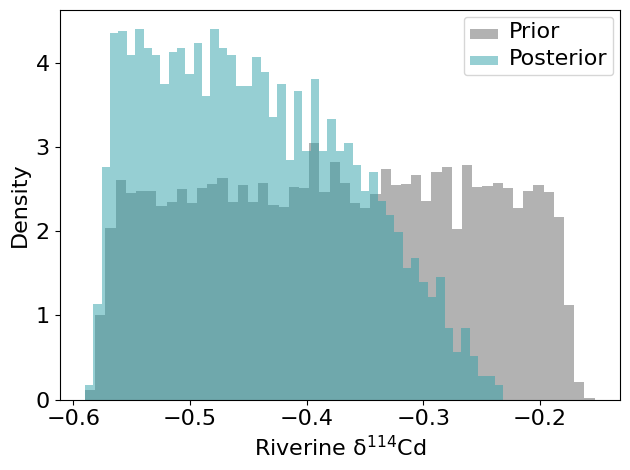

In [11]:
original_input_isotopes = json.load(open(data_directory+'/output/original_initial_conditions.json','r'))['input_isotopes']
prior_initial_input_isotopes = numpy.array([model["input_δ114Cd"][0] for model in prior_results])
posterior_initial_input_isotopes = numpy.array([model["input_δ114Cd"][0] for model in posterior_results])

figure = pyplot.figure()
axes = figure.add_subplot(111)

axes.hist(original_input_isotopes,bins=50,density=True,color="#666666",alpha=0.5)
# axes.hist(prior_initial_input_isotopes,bins=100,density=True,color="#94babd",alpha=0.5)
axes.hist(posterior_initial_input_isotopes,bins=50,density=True,color="#2ea0a8",alpha=0.5)

axes.set_xlabel("Riverine δ$^{114}$Cd")
axes.set_ylabel("Density")

# # Legend
axes.legend(["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("../../figures/cadmium_initial_input_isotopes.png",transparent=True)

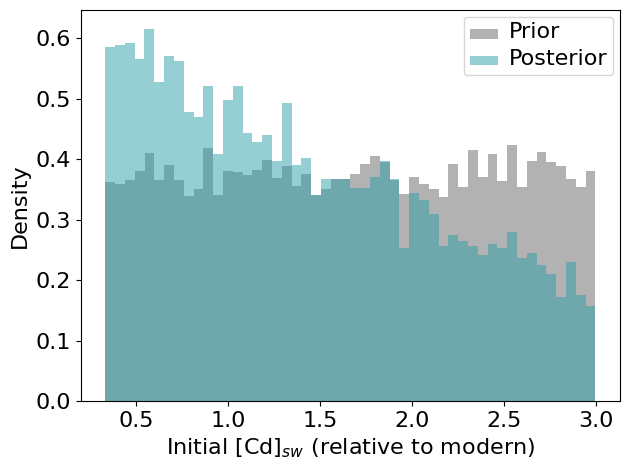

In [12]:
original_seawater_mass = json.load(open(data_directory+'/output/original_initial_conditions.json','r'))['mass_multiplier']
prior_initial_seawater_mass = numpy.array([model["seawater_mass"][0]/8.36e11 for model in prior_results])
posterior_initial_seawater_mass = numpy.array([model["seawater_mass"][0]/8.36e11 for model in posterior_results])

figure = pyplot.figure()
axes = figure.add_subplot(111)

axes.hist(original_seawater_mass,bins=50,color="#666666",alpha=0.5,density=True)
# axes.hist(prior_initial_seawater_mass,bins=20,color="#94babd",alpha=0.3)
axes.hist(posterior_initial_seawater_mass,bins=50,color="#2ea0a8",alpha=0.5,density=True)


axes.set_xlabel("Initial [Cd]$_{sw}$ (relative to modern)")
axes.set_ylabel("Density")

# Legend
axes.legend(["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("../../figures/cadmium_initial_seawater_mass.png",transparent=True)